# Transformers: a causal summary of patient history

We only need one role from the Transformer in this project: turn a variable-length clinical history into a causal state \(H_t\) that can condition downstream probabilistic models.

Self-attention compares **every token with every other token** to decide which records are relevant to each token. A causal mask then excludes future tokens from these comparisons. Given token representations \(X\), self-attention forms

\[
Q=XW_Q,\qquad K=XW_K,\qquad V=XW_V,
\]

\[
\operatorname{Attention}(Q,K,V)
=\operatorname{softmax}\left(\frac{QK^\top}{\sqrt{d_k}}+M\right)V.
\]

The matrices \(W_Q,W_K,W_V\) are **learned linear projections**, trained with the rest of the model. They turn each token into a **query** (what information it seeks), a **key** (what it can be matched against), and a **value** (the information it contributes). Entry \((i,j)\) of \(QK^\top\) scores how well token \(i\)'s query matches token \(j\)'s key; row-wise softmax turns the allowed scores into weights for a weighted sum of the values.

\(M\) is an **additive attention mask**, not a learned projection. For a causal Transformer, \(M_{ij}=0\) for allowed positions \(j\leq i\) and \(M_{ij}=-\infty\) for future positions \(j>i\). Adding it before softmax makes future-token weights exactly zero. This is what lets us train on an entire sequence in parallel while ensuring that each position uses only its own and earlier tokens, even though later tokens are present in the training batch. Tokens must be ordered by record availability, and their input features must also exclude future information to avoid leakage.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
from lifetime_clinical.tutorials.textbook import causal_attention

## Tokens and time information

A clinical token might encode an event, a measurement or a covariate update. Attention alone has no concept of order, so each token also needs temporal information. In this repo we care about two distinct clocks:

- **absolute age**: where the patient is in life, e.g. 67.4 years;
- **elapsed time**: how long since the previous observation/event.

A schematic token is therefore

\[
e_j=e_{\text{type}}+e_{\text{value}}+e_{\text{age}}+e_{\Delta t}.
\]

The output state queried at age \(t\),

\[
H_t=E_\psi(\mathcal H_{\le t},t),
\]

must not depend on future records.

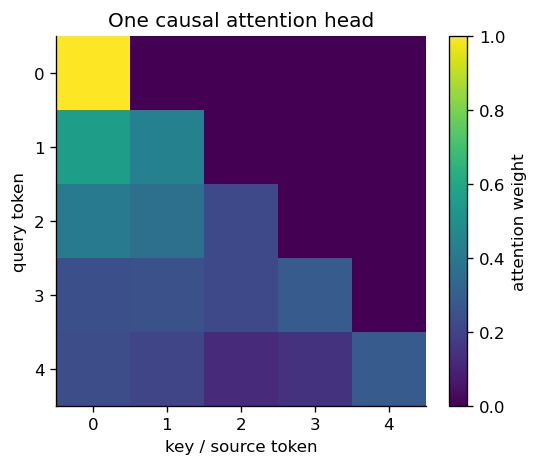

In [2]:
tokens=np.array([[1.,0.,0.,0.],[0.,1.,0.,0.],[0.,0.,1.,0.],[0.,0.,0.,1.],[1.,1.,0.,0.]])
w,_=causal_attention(tokens,seed=4)
fig,ax=plt.subplots(figsize=(5,4)); im=ax.imshow(w,vmin=0,vmax=1)
ax.set(xlabel="key / source token",ylabel="query token",title="One causal attention head")
fig.colorbar(im,ax=ax,label="attention weight"); plt.show()

## Why we use it

The important property is not that a Transformer is fashionable; it is that it gives us a flexible causal map

\[
\text{heterogeneous irregular history}\longrightarrow H_t.
\]

The downstream models then keep their probabilistic meaning:

\[
H_t\rightarrow p(\tau_{next}\mid H_t) \quad\text{(TPP)},
\]

\[
H_t\rightarrow k_\theta(\cdot,\cdot)\rightarrow GP \quad\text{(physiology)}.
\]

Attention can model long-range interactions that a fixed Hawkes kernel or a short recurrent memory may miss. Positional/time encodings distinguish identical clinical values observed at different ages.

**What the Transformer does not give us by itself:** a calibrated event-time distribution, an exact density, or a continuous-time physiological posterior. Those are supplied by the TPP/flow and GP components.

**Clinical input encoding used throughout these models.** Categories use small learned embeddings: sex, employment, record kind and event type use two coordinates; marital status and history-variable identity use three, while GP query-output identity uses two. Missing/unseen categories are explicit. A category that does not apply to a token uses a zero padding embedding. Adapter indicators are decoded to IDs before neural computation. Physiological values remain training-standardised, with explicit missingness and known-value flags. With small vocabularies, embeddings provide a compact representation; a one-hot vector followed by a linear projection already learns category vectors, so this change does not automatically improve predictions.

Age supplies a **learned continuous absolute-age encoding**, rather than a raw content feature or a sinusoidal code. A small two-layer network maps age in years into the model's hidden dimension:

\[
\mathrm{PE}_\omega(a)=W_2\tanh\!\left(W_1\frac{a}{100}+b_1\right)+b_2.
\]

History tokens add this encoding after their learned content projection. TPP-A reconstructs record ages from entry age and accumulated IATs; dynamic TPPs and GP histories use recorded ages. Equal-age records share an encoding, while the causal attention mask still prevents attending to later records. Each conditioning network replaces age scalars with learned age encodings and categorical indicators with embeddings. All encoding parameters are trained with the model. Duration/IAT inputs retain their log scaling.

The GP still uses actual age differences as its continuous covariance coordinate; output IDs select the covariance matrix. Its neural mean, feature maps and flows receive learned age and output embeddings. This removes imposed periodicity, but does not guarantee reliable extrapolation or a biologically correct ageing trajectory.